In [2]:
!pip install git+https://github.com/facebookresearch/segment-anything-2.git
!pip install opencv-python-headless


  Cloning https://github.com/facebookresearch/segment-anything-2.git to /tmp/pip-req-build-b8tj8um1
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything-2.git /tmp/pip-req-build-b8tj8um1
  Resolved https://github.com/facebookresearch/segment-anything-2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 97.4 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 67.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
!wget https://s3.unistra.fr/camma_public/datasets/endoscapes/endoscapes.zip -O /kaggle/working/endoscapes.zip
!unzip /kaggle/working/endoscapes.zip -d /kaggle/working/endoscapes


--2025-12-02 16:51:57--  https://s3.unistra.fr/camma_public/datasets/endoscapes/endoscapes.zip
Resolving s3.unistra.fr (s3.unistra.fr)... 130.79.200.152
Connecting to s3.unistra.fr (s3.unistra.fr)|130.79.200.152|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6285499749 (5.9G) [application/zip]
Saving to: ‘/kaggle/working/endoscapes.zip’

orking/endoscapes.z  58%[==========>         ]   3.41G  25.3MB/s    eta 2m 6s  

Found 36697 files/sample dir


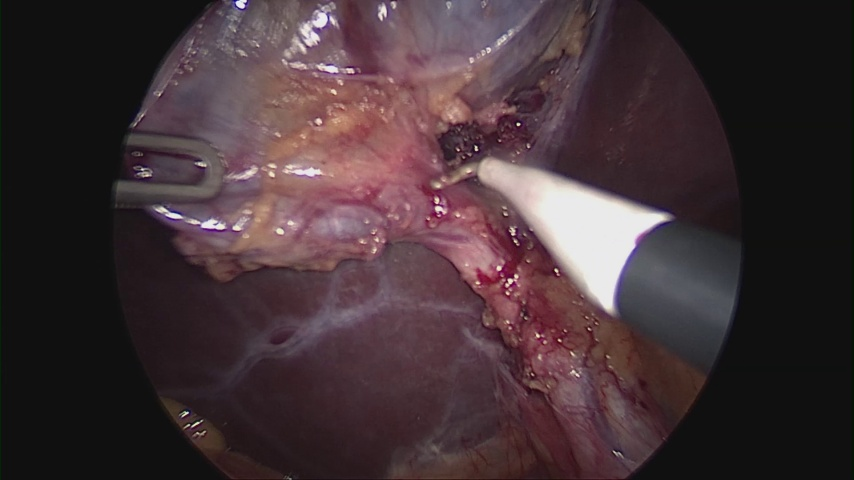

In [3]:
from PIL import Image
import os

IMG_DIR = "/kaggle/working/endoscapes/endoscapes/train"

# pick a subfolder that contains images, e.g. train/ or train_0
sample_path = IMG_DIR

files = os.listdir(sample_path)
print("Found", len(files), "files/sample dir")
first = files[0]

img = Image.open(os.path.join(sample_path, first))
display(img)


In [4]:
!ls -la /kaggle/working/endoscapes/endoscapes/train


total 4011696
drwxrwxrwx  2 root root 1073152 Dec 14  2023 .
drwxr-xr-x 12 root root    4096 Dec  2 11:47 ..
-rwxrwxrwx  1 root root  131121 Dec 13  2023 100_27200.jpg
-rwxrwxrwx  1 root root  122687 Dec 13  2023 100_27225.jpg
-rwxrwxrwx  1 root root  116031 Dec 13  2023 100_27250.jpg
-rwxrwxrwx  1 root root  126038 Dec 13  2023 100_27275.jpg
-rwxrwxrwx  1 root root  121995 Dec 13  2023 100_27300.jpg
-rwxrwxrwx  1 root root  117925 Dec 13  2023 100_27325.jpg
-rwxrwxrwx  1 root root  118627 Dec 13  2023 100_27350.jpg
-rwxrwxrwx  1 root root  115543 Dec 13  2023 100_27375.jpg
-rwxrwxrwx  1 root root  118977 Dec 13  2023 100_27400.jpg
-rwxrwxrwx  1 root root  120974 Dec 13  2023 100_27425.jpg
-rwxrwxrwx  1 root root  116443 Dec 13  2023 100_27450.jpg
-rwxrwxrwx  1 root root  120130 Dec 13  2023 100_27475.jpg
-rwxrwxrwx  1 root root  124203 Dec 13  2023 100_27500.jpg
-rwxrwxrwx  1 root root  122332 Dec 13  2023 100_27525.jpg
-rwxrwxrwx  1 root root  116537 Dec 13  2023 100_27550.jpg
-rwxrw

Number of images: 36694


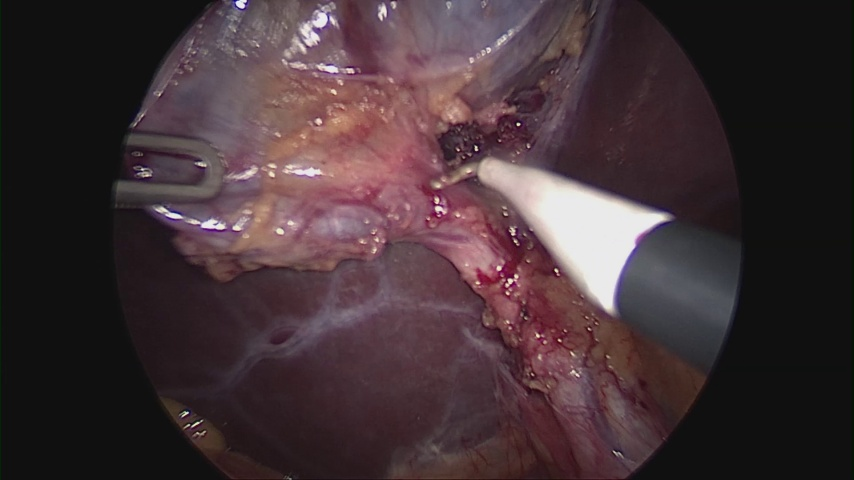

In [12]:
import os
from PIL import Image

IMG_DIR = "/kaggle/working/endoscapes/endoscapes/train"

files = [f for f in os.listdir(IMG_DIR) if f.endswith(".jpg")]
print("Number of images:", len(files))

img = Image.open(os.path.join(IMG_DIR, files[0]))
display(img)



In [13]:
# === Build multi-label CSVs from Endoscapes segmentation masks ===
# Kaggle-ready: assumes you unzipped into /kaggle/working/endoscapes/endoscapes
# Produces CSVs in /kaggle/working/endoscapes_labels/

import os, re, sys, math
from pathlib import Path
from tqdm.auto import tqdm
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

ROOT = Path('/kaggle/working/endoscapes/endoscapes')
OUT_DIR = Path('/kaggle/working/endoscapes_labels')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1) Parse seg_label_map.txt to build id -> name mapping
label_map_path = ROOT / 'seg_label_map.txt'
if not label_map_path.exists():
    raise FileNotFoundError(f"seg_label_map.txt not found at {label_map_path}. Check dataset root.")

label_map = {}
with open(label_map_path, 'r', encoding='utf-8') as f:
    for line in f:
        line = line.strip()
        if not line:
            continue
        # Common formats: "0 background", "0: background", "0 background\n", "0,background"
        # We'll extract the first integer and the rest as the name
        m = re.match(r'^\s*([0-9]+)\s*[:,-]?\s*(.+)$', line)
        if m:
            cid = int(m.group(1))
            name = m.group(2).strip()
            # sanitize name to be a valid column (no spaces, lower)
            colname = re.sub(r'\s+', '_', name).lower()
            label_map[cid] = colname
        else:
            # fallback: try splitting by whitespace
            parts = line.split()
            if parts and parts[0].isdigit():
                cid = int(parts[0])
                name = "_".join(parts[1:]) if len(parts) > 1 else f"class_{cid}"
                label_map[cid] = re.sub(r'\s+', '_', name).lower()

# Sort map by id
label_map = dict(sorted(label_map.items(), key=lambda kv: kv[0]))
print("Parsed label map (id -> name):")
for k,v in label_map.items():
    print(f"  {k} -> {v}")

# Exclude background if present (commonly id 0)
bg_ids = [k for k,v in label_map.items() if 'background' in v or v in ('bg','background')]
bg_ids = set(bg_ids)
print("Background ids detected:", bg_ids)

# Create tool columns (exclude background)
tool_ids = [k for k in label_map.keys() if k not in bg_ids]
tool_cols = [label_map[k] for k in tool_ids]

print(f"Detected {len(tool_cols)} tool classes:", tool_cols)

# 2) Utility to find mask for an image
def find_mask_for_image(image_path: Path, seg_dir: Path):
    """
    Given an image Path and a segmentation folder, try to find the corresponding mask file.
    Typical mapping: image '12345.jpg' -> mask '12345.png' or same stem with other extension.
    Returns Path or None if not found.
    """
    stem = image_path.stem
    # try common extensions
    for ext in ['.png', '.jpg', '.jpeg', '.tif', '.tiff', '.npy']:
        cand = seg_dir / (stem + ext)
        if cand.exists():
            return cand
    # fallback: search for any file starting with stem
    for p in seg_dir.glob(stem + '*'):
        if p.is_file():
            return p
    return None

# 3) Function: build CSV for a split
def build_labels_for_split(split_name: str):
    """
    split_name: 'train', 'val', or 'test'
    Assumes images in ROOT/<split_name> and masks in ROOT/<split_name>_seg
    """
    img_dir = ROOT / split_name
    seg_dir = ROOT / f"{split_name}_seg"
    assert img_dir.exists(), f"Image dir not found: {img_dir}"
    assert seg_dir.exists(), f"Seg dir not found: {seg_dir}"
    
    img_files = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in ('.jpg', '.png', '.jpeg')]
    print(f"\nProcessing split '{split_name}' — images: {len(img_files)}, seg dir: {seg_dir}")

    rows = []
    missing_mask = 0
    for img_path in tqdm(img_files, desc=f"labels:{split_name}", total=len(img_files)):
        mask_path = find_mask_for_image(img_path, seg_dir)
        row = {'filename': img_path.name}
        # default zeros
        for col in tool_cols:
            row[col] = 0
        if mask_path is None:
            missing_mask += 1
            rows.append(row)
            continue
        # load mask (handle paletted or integer masks)
        try:
            if mask_path.suffix.lower() == '.npy':
                mask = np.load(mask_path)
            else:
                mimg = Image.open(mask_path)
                # convert to numpy of ints (if palette, convert to 'L' first)
                if mimg.mode == 'P':
                    mimg = mimg.convert('L')
                mask = np.array(mimg)
        except Exception as e:
            # mask load failed: leave zeros, but record
            missing_mask += 1
            rows.append(row)
            continue
        # get unique labels present
        unique_ids = np.unique(mask)
        # assign columns for any intersection with known tool_ids
        for cid in tool_ids:
            if cid in unique_ids:
                col = label_map[cid]
                row[col] = 1
        rows.append(row)

    df = pd.DataFrame(rows)
    out_csv = OUT_DIR / f"labels_{split_name}.csv"
    df.to_csv(out_csv, index=False)
    print(f"Saved {len(df)} rows to {out_csv} (masks missing or failed: {missing_mask})")
    return df

# 4) Run for train/val/test (but only run splits that exist)
for split in ['train', 'val', 'test']:
    if (ROOT / split).exists() and (ROOT / f"{split}_seg").exists():
        _ = build_labels_for_split(split)
    else:
        print(f"Skipping {split} because either {ROOT/split} or {ROOT/(split+'_seg')} is missing.")

# 5) Quick sanity checks and examples
print("\nExample rows from train labels (top 5):")
train_csv = OUT_DIR / "labels_train.csv"
if train_csv.exists():
    df_train = pd.read_csv(train_csv)
    display(df_train.head())

    # show a sample image and its mask overlay
    sample = df_train.sample(1).iloc[0]
    fname = sample['filename']
    img_path = ROOT / 'train' / fname
    mask_path = find_mask_for_image(img_path, ROOT / 'train_seg')
    print("Sample:", fname)
    print("Image exists:", img_path.exists(), "Mask found:", mask_path)
    if img_path.exists() and mask_path:
        img = Image.open(img_path).convert('RGB')
        mimg = Image.open(mask_path)
        if mimg.mode == 'P':
            mimg = mimg.convert('L')
        mask = np.array(mimg)
        plt.figure(figsize=(10,5))
        plt.subplot(1,2,1)
        plt.title('Image')
        plt.imshow(img); plt.axis('off')
        plt.subplot(1,2,2)
        plt.title('Mask (unique ids: {})'.format(np.unique(mask).tolist()))
        plt.imshow(mask); plt.axis('off')
        plt.tight_layout()
else:
    print("train CSV not found; something went wrong.")

print("\nAll done — CSVs are in:", OUT_DIR)


Parsed label map (id -> name):
Background ids detected: set()
Detected 0 tool classes: []

Processing split 'train' — images: 36694, seg dir: /kaggle/working/endoscapes/endoscapes/train_seg


labels:train:   0%|          | 0/36694 [00:00<?, ?it/s]

Saved 36694 rows to /kaggle/working/endoscapes_labels/labels_train.csv (masks missing or failed: 26314)

Processing split 'val' — images: 12372, seg dir: /kaggle/working/endoscapes/endoscapes/val_seg


labels:val:   0%|          | 0/12372 [00:00<?, ?it/s]

Saved 12372 rows to /kaggle/working/endoscapes_labels/labels_val.csv (masks missing or failed: 10062)

Processing split 'test' — images: 9747, seg dir: /kaggle/working/endoscapes/endoscapes/test_seg


labels:test:   0%|          | 0/9747 [00:00<?, ?it/s]

Saved 9747 rows to /kaggle/working/endoscapes_labels/labels_test.csv (masks missing or failed: 7497)

Example rows from train labels (top 5):


,filename
0,99_26875.jpg
1,4_30050.jpg
2,1_32450.jpg
3,46_17750.jpg
4,21_57250.jpg


Sample: 29_38200.jpg
Image exists: True Mask found: None

All done — CSVs are in: /kaggle/working/endoscapes_labels


In [15]:

# Diagnostic + robust label-builder for Endoscapes
from pathlib import Path
import re, os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

ROOT = Path('/kaggle/working/endoscapes/endoscapes')
LABEL_MAP = ROOT / 'seg_label_map.txt'
OUT_DIR = Path('/kaggle/working/endoscapes_labels')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT exists:", ROOT.exists())
print("Label map exists:", LABEL_MAP.exists())
print("\n--- First 100 lines of seg_label_map.txt (if present) ---")
if LABEL_MAP.exists():
    with open(LABEL_MAP, 'r', encoding='utf-8', errors='ignore') as f:
        for i, line in enumerate(f):
            if i >= 100: break
            print(f"{i+1:03d}: {line.strip()}")
else:
    print("seg_label_map.txt not found at expected location:", LABEL_MAP)

# Show a quick view of seg directories and some file counts and examples
for split in ['train_seg','val_seg','test_seg']:
    p = ROOT / split
    if not p.exists():
        print(f"\n{split} : not found")
        continue
    # count files recursively
    files = list(p.rglob('*'))
    file_count = sum(1 for f in files if f.is_file())
    print(f"\n{split} : found {file_count} files under {p}")
    # show up to 10 sample paths
    samples = [str(f.relative_to(ROOT)) for f in files if f.is_file()][:10]
    print(" sample files (first 10):")
    for s in samples:
        print("   ", s)

# Robust label map parsing (try multiple patterns)
label_map = {}
if LABEL_MAP.exists():
    text = LABEL_MAP.read_text(encoding='utf-8', errors='ignore').splitlines()
    for line in text:
        line = line.strip()
        if not line:
            continue
        # try common patterns
        m = re.match(r'^\s*([0-9]+)\s*[:\-\s,]+\s*(.+)$', line)
        if m:
            cid = int(m.group(1)); name = m.group(2).strip()
            col = re.sub(r'\W+','_', name).strip('_').lower() or f"class_{cid}"
            label_map[cid] = col
            continue
        # fallback: "class_name id" or "id class_name"
        parts = re.split(r'\s+', line)
        if parts and parts[0].isdigit():
            cid = int(parts[0]); name = "_".join(parts[1:]) or f"class_{cid}"
            label_map[cid] = re.sub(r'\W+','_', name).strip('_').lower()
        elif parts and parts[-1].isdigit():
            cid = int(parts[-1]); name = "_".join(parts[:-1]) or f"class_{cid}"
            label_map[cid] = re.sub(r'\W+','_', name).strip('_').lower()

print("\nParsed label_map (id -> colname)  ({} entries)".format(len(label_map)))
for k,v in sorted(label_map.items()):
    print(f"  {k} -> {v}")

# If label_map is empty, try to infer classes by scanning unique values in a small sample of masks
if not label_map:
    print("\nlabel_map empty. Let's sample some masks to infer unique ids and print them.")
    seg_sample_dir = ROOT / 'train_seg'
    if seg_sample_dir.exists():
        # find up to 200 masks and collect unique IDs
        uids = set()
        cnt = 0
        for p in seg_sample_dir.rglob('*'):
            if not p.is_file(): continue
            if p.suffix.lower() not in ('.png','.jpg','.jpeg','.tif','.tiff','.npy'): 
                continue
            try:
                if p.suffix.lower() == '.npy':
                    arr = np.load(p)
                else:
                    img = Image.open(p)
                    if img.mode == 'P':
                        img = img.convert('L')
                    arr = np.array(img)
                uids.update(np.unique(arr).tolist())
                cnt += 1
                if cnt >= 200:
                    break
            except Exception as e:
                pass
        print("Sampled {} mask files; unique ids seen in sample: {}".format(cnt, sorted(list(uids))[:50]))
        if cnt==0:
            print("No masks readable in train_seg; maybe masks are stored elsewhere or use an unusual extension.")
    else:
        print("train_seg not found; cannot sample masks.")

# Now build labels robustly using recursive mask search
def find_mask_recursive(image_path: Path, seg_dir: Path):
    """Search recursively inside seg_dir for files whose stem matches the image stem."""
    stem = image_path.stem
    # fast try: same folder name under seg_dir
    # but do a recursive glob as fallback
    # Prefer same-stem files first
    for ext in ['.png', '.jpg', '.jpeg', '.tif', '.tiff', '.npy']:
        cand = seg_dir / (stem + ext)
        if cand.exists():
            return cand
    # recursive search by stem anywhere under seg_dir (this is slower but robust)
    for p in seg_dir.rglob(stem + '*'):
        if p.is_file():
            return p
    # no mask
    return None

# quick cross-check: try to map a few train images to masks and show examples
img_dir = ROOT / 'train'
seg_dir = ROOT / 'train_seg'
if img_dir.exists() and seg_dir.exists():
    imgs = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in ('.jpg','.png','.jpeg')]
    print("\nChecking 10 random images from train and whether recursive mask search finds masks...")
    sample_imgs = imgs[:10]
    mapped = 0
    for p in sample_imgs:
        m = find_mask_recursive(p, seg_dir)
        print(p.name, "->", (str(m.relative_to(ROOT)) if m else "MISSING"))
        if m: mapped += 1
    print("mapped examples:", mapped, "/", len(sample_imgs))

# If everything looks okay, offer to rebuild CSVs using recursive search; if user wants, run next.
print("\nDIAGNOSTIC COMPLETE.")
print("If you want, run the robust CSV builder now (it will use recursive search and produce labels_train.csv etc).")


ROOT exists: True
Label map exists: True

--- First 100 lines of seg_label_map.txt (if present) ---
001: background
002: cystic_plate
003: calot_triangle
004: cystic_artery
005: cystic_duct
006: gallbladder
007: tool

train_seg : found 10383 files under /kaggle/working/endoscapes/endoscapes/train_seg
 sample files (first 10):
    train_seg/4_30050.jpg
    train_seg/116_34500.jpg
    train_seg/116_30725.jpg
    train_seg/105_16475.jpg
    train_seg/84_23425.jpg
    train_seg/83_59050.jpg
    train_seg/13_47325.jpg
    train_seg/119_80800.jpg
    train_seg/43_9175.jpg
    train_seg/4_22500.jpg

val_seg : found 2311 files under /kaggle/working/endoscapes/endoscapes/val_seg
 sample files (first 10):
    val_seg/131_51325.jpg
    val_seg/126_11300.jpg
    val_seg/126_11875.jpg
    val_seg/142_36575.jpg
    val_seg/144_16575.jpg
    val_seg/126_11450.jpg
    val_seg/153_18775.jpg
    val_seg/142_29200.jpg
    val_seg/142_33650.jpg
    val_seg/142_29375.jpg

test_seg : found 2251 files under 

In [17]:
# FAST heuristic detector for Endoscapes masks (sampling-based, avoids full-array np.unique)
from pathlib import Path
import numpy as np
from PIL import Image
from collections import Counter
import random
import math
import os

ROOT = Path('/kaggle/working/endoscapes/endoscapes')
SEG_DIR = ROOT / 'train_seg'
LABEL_MAP_PATH = ROOT / 'seg_label_map.txt'

# Config: reduce these for faster runs if needed
NUM_MASK_SAMPLES = 100   # how many mask files to sample (100 is a good tradeoff)
PIXEL_SAMPLE_PER_MASK = 5000  # sample this many pixels per mask (<= total pixels). 5k is plenty

# Read and print seg_label_map.txt (for manual fallback)
if LABEL_MAP_PATH.exists():
    print("First lines of seg_label_map.txt:")
    with open(LABEL_MAP_PATH, 'r', encoding='utf-8', errors='ignore') as f:
        for i, line in enumerate(f):
            if i >= 20: break
            print(line.strip())
else:
    print("seg_label_map.txt not found at", LABEL_MAP_PATH)

# gather mask files
if not SEG_DIR.exists():
    raise RuntimeError(f"Seg dir not found: {SEG_DIR}")

mask_files = [p for p in SEG_DIR.rglob('*') if p.is_file() and p.suffix.lower() in ('.png','.jpg','.jpeg','.tif','.tiff','.npy')]
print("Total mask files found (recursive):", len(mask_files))
if len(mask_files) == 0:
    raise RuntimeError("No mask files found under train_seg")

# limit the number of mask files we sample
mask_files = mask_files[:NUM_MASK_SAMPLES]

sampled_values = Counter()
masks_read = 0
for p in mask_files:
    try:
        # load mask as numpy ints
        if p.suffix.lower() == '.npy':
            arr = np.load(p)
        else:
            img = Image.open(p)
            if img.mode == 'P':
                img = img.convert('L')
            arr = np.array(img)
        if arr is None:
            continue
        flat = arr.reshape(-1)
        n = flat.size
        if n == 0:
            continue
        # pick indices to sample (uniform)
        if n <= PIXEL_SAMPLE_PER_MASK:
            sampled = np.unique(flat).tolist()  # if tiny, we can take uniques
        else:
            # sample indices without replacement
            idx = np.random.choice(n, size=min(PIXEL_SAMPLE_PER_MASK, n), replace=False)
            sampled = np.unique(flat[idx]).tolist()
        sampled_values.update(map(int, sampled))
        masks_read += 1
    except Exception as e:
        # skip problematic files
        continue

print("Masks read (sampled):", masks_read)
print("Number of distinct sampled pixel values found:", len(sampled_values))
print("Most common sampled values (top 50):")
print(sorted(sampled_values.items(), key=lambda kv: -kv[1])[:50])

# Define heuristics to test on raw sampled values
def apply_heur(value, name):
    if name == 'raw': return value
    if name == 'mod256': return value % 256
    if name == 'div256': return value // 256
    if name == 'mod1000': return value % 1000
    if name == 'div1000': return value // 1000
    if name == 'mod100': return value % 100
    if name == 'div100': return value // 100
    return value

heuristics = ['raw','mod256','div256','mod1000','div1000','mod100','div100']

# Evaluate heuristics: how many mapped values are small integers (likely class ids)
heur_stats = {}
sampled_vals_list = list(sampled_values.keys())
for h in heuristics:
    mapped = [apply_heur(v,h) for v in sampled_vals_list]
    unique_mapped = set(mapped)
    # heur score: fraction of mapped values that are <= 50 (heuristic: class ids are small)
    small_count = sum(1 for v in unique_mapped if 0 <= int(v) <= 50)
    heur_stats[h] = {
        'unique_mapped_count': len(unique_mapped),
        'small_mapped_count': small_count,
        'frac_small': small_count / max(1, len(unique_mapped))
    }

print("\nHeuristic summary (higher frac_small suggests likely decode):")
for h,st in sorted(heur_stats.items(), key=lambda kv: -kv[1]['frac_small']):
    print(f"  {h:8s} | unique_mapped={st['unique_mapped_count']:4d} small_mapped={st['small_mapped_count']:4d} frac_small={st['frac_small']:.3f}")

# Pick best heuristic by frac_small
best = max(heur_stats.keys(), key=lambda k: heur_stats[k]['frac_small'])
print("\nBest heuristic:", best)

# Quick demonstration of mapping a few sample masks using the chosen heuristic
print("\nDemo: mapping a few sample mask files with heuristic", best)
for p in mask_files[:10]:
    try:
        if p.suffix.lower() == '.npy':
            arr = np.load(p)
        else:
            img = Image.open(p)
            if img.mode == 'P':
                img = img.convert('L')
            arr = np.array(img)
        vals = np.unique(arr.reshape(-1)[:10000]) if arr.size>10000 else np.unique(arr)
        mapped_vals = sorted(set(apply_heur(int(v), best) for v in (vals.tolist() if hasattr(vals,'tolist') else vals)))
        print(p.name, "-> sample mapped values (up to 30):", mapped_vals[:30])
    except Exception as e:
        print("error reading", p, e)

print("\nIf the chosen heuristic looks good, we can now run a full CSV builder using it.")


First lines of seg_label_map.txt:
background
cystic_plate
calot_triangle
cystic_artery
cystic_duct
gallbladder
tool
Total mask files found (recursive): 10380
Masks read (sampled): 100
Number of distinct sampled pixel values found: 256
Most common sampled values (top 50):
[(33, 99), (39, 99), (40, 99), (42, 99), (43, 99), (44, 99), (45, 99), (46, 99), (47, 99), (48, 99), (49, 99), (50, 99), (51, 99), (52, 99), (53, 99), (54, 99), (55, 99), (56, 99), (57, 99), (58, 99), (59, 99), (60, 99), (61, 99), (62, 99), (63, 99), (64, 99), (65, 99), (66, 99), (67, 99), (68, 99), (69, 99), (70, 99), (71, 99), (72, 99), (73, 99), (74, 99), (75, 99), (76, 99), (77, 99), (78, 99), (79, 99), (80, 99), (81, 99), (82, 99), (83, 99), (84, 99), (85, 99), (86, 99), (87, 99), (88, 99)]

Heuristic summary (higher frac_small suggests likely decode):
  div256   | unique_mapped=   1 small_mapped=   1 frac_small=1.000
  div1000  | unique_mapped=   1 small_mapped=   1 frac_small=1.000
  div100   | unique_mapped=   

In [18]:
# Robust CSV builder that prefers 'semseg' if available, else tries palette/instance decode.
from pathlib import Path
import numpy as np
from PIL import Image
from collections import Counter
import pandas as pd
from tqdm.auto import tqdm
import os

ROOT = Path('/kaggle/working/endoscapes/endoscapes')
OUT_DIR = Path('/kaggle/working/endoscapes_labels')
OUT_DIR.mkdir(parents=True, exist_ok=True)

# known semantic class names from seg_label_map.txt (in order)
class_names = ['background','cystic_plate','calot_triangle','cystic_artery','cystic_duct','gallbladder','tool']

def load_mask_np(p: Path):
    try:
        if p.suffix.lower() == '.npy':
            arr = np.load(p)
        else:
            img = Image.open(p)
            # if paletted, convert to palette indices (mode 'P' -> convert('L') gives indices)
            if img.mode == 'P':
                img = img.convert('L')
            arr = np.array(img)
        if not np.issubdtype(arr.dtype, np.integer):
            arr = arr.astype(np.int32)
        return arr
    except Exception as e:
        return None

def find_mask_recursive(image_path: Path, seg_dir: Path):
    stem = image_path.stem
    for ext in ['.png','.jpg','.jpeg','.tif','.tiff','.npy']:
        cand = seg_dir / (stem + ext)
        if cand.exists():
            return cand
    for p in seg_dir.rglob(stem + '*'):
        if p.is_file():
            return p
    return None

# 1) helper to test whether a seg folder contains semantic labels 0..N
def test_semantic_folder(seg_dir: Path, sample_limit=200):
    if not seg_dir.exists():
        return False, {}
    mask_files = [p for p in seg_dir.rglob('*') if p.is_file() and p.suffix.lower() in ('.png','.jpg','.jpeg','.tif','.tiff','.npy')]
    if len(mask_files) == 0:
        return False, {}
    mask_files = mask_files[:sample_limit]
    seen = set()
    for p in mask_files:
        arr = load_mask_np(p)
        if arr is None: continue
        # sample some pixels if huge
        flat = arr.reshape(-1)
        if flat.size > 20000:
            idx = np.random.choice(flat.size, 20000, replace=False)
            vals = np.unique(flat[idx])
        else:
            vals = np.unique(flat)
        seen.update(map(int, vals.tolist()))
        # early stop if we already see small ids 0..7
        if any(v in seen for v in range(0, len(class_names))):
            # still collect more to be sure
            pass
    # decide whether this folder likely contains semantic ids
    # heuristic: if we see mostly values within small range (0..20) and 0..6 present -> semantic
    small_vals = [v for v in seen if 0 <= v <= 50]
    frac_small = len(small_vals) / max(1, len(seen))
    has_core = all(v in seen for v in range(0, len(class_names)))  # check all 0..6 present
    return (frac_small > 0.6 and has_core), {'seen_count': len(seen), 'small_count': len(small_vals), 'has_core': has_core, 'seen_sample': sorted(list(seen))[:50]}

# Check semseg, insseg, train_seg
candidates = {}
for name in ['semseg','insseg','train_seg']:
    seg_dir = ROOT / name
    ok, info = test_semantic_folder(seg_dir)
    candidates[name] = (seg_dir.exists(), ok, info)

print("Folder checks (exists, looks_semantic, info):")
for k,v in candidates.items():
    print(f"  {k}: exists={v[0]}, looks_semantic={v[1]}, info={v[2]}")

# Prefer semseg if semantic
chosen_seg = None
for pref in ['semseg','insseg','train_seg']:
    exists, looks_sem, info = candidates[pref]
    if exists and looks_sem:
        chosen_seg = ROOT / pref
        print(f"Selecting semantic folder: {pref}")
        break

# If none looked semantic, fall back to semseg if it exists else train_seg
if chosen_seg is None:
    if (ROOT / 'semseg').exists():
        chosen_seg = ROOT / 'semseg'
        print("No folder confidently semantic; defaulting to 'semseg' (exists).")
    else:
        chosen_seg = ROOT / 'train_seg'
        print("No semantic folder detected; falling back to 'train_seg' (will attempt palette decode).")

# If chosen_seg likely semantic, we can simply read unique values per mask and map 0..6 to class presence
def build_from_semantic_folder(split_name):
    img_dir = ROOT / split_name
    seg_dir = ROOT / f"{split_name}_seg"
    if not img_dir.exists() or not seg_dir.exists():
        print(f"Skipping {split_name}: missing images or seg folder ({img_dir}, {seg_dir})")
        return None
    imgs = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in ('.jpg','.png','.jpeg')]
    rows = []
    missing = 0
    for p in tqdm(imgs, desc=f"labels:{split_name}"):
        mp = find_mask_recursive(p, seg_dir)
        row = {'filename': p.name}
        for cname in class_names:
            row[cname] = 0
        if mp is None:
            missing += 1
            rows.append(row); continue
        arr = load_mask_np(mp)
        if arr is None:
            missing += 1
            rows.append(row); continue
        unique = np.unique(arr)
        for cid in range(len(class_names)):
            if cid in unique:
                row[class_names[cid]] = 1
        rows.append(row)
    df = pd.DataFrame(rows)
    out = OUT_DIR / f"labels_{split_name}.csv"
    df.to_csv(out, index=False)
    print(f"Saved {len(df)} rows to {out} (missing masks: {missing})")
    return df

# If chosen_seg is semseg/insseg and looks semantic -> use it
if chosen_seg.name in ('semseg','insseg'):
    print("Building labels from semantic folder:", chosen_seg.name)
    for split in ['train','val','test']:
        if (ROOT / split).exists() and (ROOT / f"{split}_seg").exists():
            build_from_semantic_folder(split)
else:
    # fallback palette/instance decode strategy
    print("FALLBACK: attempting palette/instance decode from train_seg (this may be approximate).")
    # We'll try two simple decodes and pick the better:
    #    A) take palette index raw value and map {1..7} -> classes if present
    #    B) take raw value % 100 -> map small values to classes
    def attempt_decode_and_build(split_name, decode_fn, decode_name):
        img_dir = ROOT / split_name
        seg_dir = ROOT / f"{split_name}_seg"
        if not img_dir.exists() or not seg_dir.exists():
            return None
        imgs = [p for p in img_dir.iterdir() if p.is_file() and p.suffix.lower() in ('.jpg','.png','.jpeg')]
        rows = []; missing=0; class_presence = Counter()
        for p in tqdm(imgs, desc=f"{decode_name}:{split_name}"):
            mp = find_mask_recursive(p, seg_dir)
            row = {'filename': p.name}
            for cname in class_names:
                row[cname] = 0
            if mp is None:
                missing += 1; rows.append(row); continue
            arr = load_mask_np(mp)
            if arr is None:
                missing += 1; rows.append(row); continue
            mapped = decode_fn(arr)
            for cid in range(len(class_names)):
                if cid in np.unique(mapped):
                    row[class_names[cid]] = 1
                    class_presence[class_names[cid]] += 1
            rows.append(row)
        df = pd.DataFrame(rows)
        out = OUT_DIR / f"labels_{split_name}_{decode_name}.csv"
        df.to_csv(out, index=False)
        print(f"Saved {len(df)} rows to {out} (missing masks: {missing})")
        print("Sample class presence:", {k:v for k,v in class_presence.most_common()})
        return df

    # decode A: raw palette index (assume palette index equals class id)
    def decode_raw(arr):
        return arr  # raw pixel values

    # decode B: collapse by value % 100 (some instance encodings use large numbers: we try modulus)
    def decode_mod100(arr):
        return (arr % 100).astype(np.int32)

    # Try both on a single split (train) with small sample to decide which is better
    print("Testing raw vs mod100 decode on a small sample of train images (this is approximate).")
    sample_imgs = [p for p in (ROOT/'train').iterdir() if p.is_file()][:200]
    raw_hits = 0; mod_hits = 0; total = 0
    for p in sample_imgs:
        mp = find_mask_recursive(p, ROOT/'train_seg')
        if mp is None: continue
        arr = load_mask_np(mp)
        if arr is None: continue
        unique = np.unique(arr)
        # count how many of our known class indices 0..6 appear under each decode
        raw_mapped = set(np.unique(decode_raw(unique)).tolist())
        mod_mapped = set(np.unique(decode_mod100(unique)).tolist())
        # measure how many of 0..6 present
        raw_hits += sum(1 for v in range(len(class_names)) if v in raw_mapped)
        mod_hits += sum(1 for v in range(len(class_names)) if v in mod_mapped)
        total += 1
    print("raw_hits, mod_hits, total_samples:", raw_hits, mod_hits, total)
    # pick decode with higher hits
    chosen_decode = decode_raw if raw_hits >= mod_hits else decode_mod100
    chosen_name = 'raw' if raw_hits >= mod_hits else 'mod100'
    print("Chosen decode:", chosen_name)
    # Build CSVs using chosen decode
    for split in ['train','val','test']:
        if (ROOT / split).exists() and (ROOT / f"{split}_seg").exists():
            attempt_decode_and_build(split, chosen_decode, chosen_name)

print("\nDone. CSVs are in:", OUT_DIR)


Folder checks (exists, looks_semantic, info):
  semseg: exists=True, looks_semantic=True, info={'seen_count': 9, 'small_count': 8, 'has_core': True, 'seen_sample': [0, 1, 2, 3, 4, 5, 6, 7, 255]}
  insseg: exists=True, looks_semantic=False, info={'seen_count': 2, 'small_count': 2, 'has_core': False, 'seen_sample': [0, 1]}
  train_seg: exists=True, looks_semantic=False, info={'seen_count': 256, 'small_count': 51, 'has_core': True, 'seen_sample': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49]}
Selecting semantic folder: semseg
Building labels from semantic folder: semseg


labels:train:   0%|          | 0/36694 [00:00<?, ?it/s]

Saved 36694 rows to /kaggle/working/endoscapes_labels/labels_train.csv (missing masks: 26314)


labels:val:   0%|          | 0/12372 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [21]:
# Cell 1: build SMALL subset of images that have masks (fast)
from pathlib import Path
import random, os
import pandas as pd
from PIL import Image
import numpy as np
from tqdm.auto import tqdm

ROOT = Path('/kaggle/working/endoscapes/endoscapes')
SEG_DIR = ROOT / 'train_seg'   # fallback seg folder we used
OUT_DIR = Path('/kaggle/working/endoscapes_small')
OUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_SIZE = 1000   # <--- change this to 200 / 500 / 2000 as you like

# class names (semantic targets)
class_names = ['background','cystic_plate','calot_triangle','cystic_artery','cystic_duct','gallbladder','tool']

def load_mask_np(p):
    try:
        if p.suffix.lower() == '.npy':
            arr = np.load(p)
        else:
            img = Image.open(p)
            if img.mode == 'P':
                img = img.convert('L')
            arr = np.array(img)
        return arr
    except:
        return None

# Build mask index: stem -> mask path (fast lookup)
mask_index = {}
for p in SEG_DIR.rglob('*'):
    if not p.is_file(): continue
    if p.suffix.lower() not in ('.png','.jpg','.jpeg','.tif','.tiff','.npy'): continue
    stem = p.stem
    if stem not in mask_index:
        mask_index[stem] = p
print("Mask stems indexed:", len(mask_index))

# get list of all train images that have a mask
IMG_DIR = ROOT / 'train'
imgs = [p for p in IMG_DIR.iterdir() if p.is_file() and p.suffix.lower() in ('.jpg','.jpeg','.png')]
imgs_with_mask = [p for p in imgs if p.stem in mask_index]
print("Train images total:", len(imgs), "with masks:", len(imgs_with_mask))

# sample the subset (deterministic seed)
random.seed(42)
if len(imgs_with_mask) == 0:
    raise RuntimeError("No train images found with masks in train_seg. Check paths.")
sampled = imgs_with_mask if SAMPLE_SIZE is None else random.sample(imgs_with_mask, min(SAMPLE_SIZE, len(imgs_with_mask)))
print("Using subset size:", len(sampled))

# build labels for the sampled set
rows = []
for p in tqdm(sampled, desc="building subset labels"):
    mp = mask_index.get(p.stem, None)
    row = {'filename': p.name}
    # default zeros
    for cname in class_names:
        row[cname] = 0
    if mp is None:
        # skip (shouldn't happen)
        continue
    arr = load_mask_np(mp)
    if arr is None:
        continue
    unique = np.unique(arr)
    # Basic decode heuristics (same as before): prefer small ids 0..6, else try mod100
    mapped_ids = set()
    if any(int(v) in range(0, len(class_names)) for v in unique):
        for cid in range(len(class_names)):
            if cid in unique:
                row[class_names[cid]] = 1
    elif any(int(v) in range(1, len(class_names)+1) for v in unique):
        for cid in range(1, len(class_names)+1):
            if cid in unique:
                mapped = cid-1
                if 0 <= mapped < len(class_names):
                    row[class_names[mapped]] = 1
    else:
        # fallback: collapse by %100 and mark any small code
        mapped = set(int(v % 100) for v in unique)
        for mid in mapped:
            if 0 <= mid < len(class_names):
                row[class_names[mid]] = 1
        # if still all zeros but mask nonzero, mark 'tool' conservatively
        if all(row[c]==0 for c in class_names) and np.any(arr != 0):
            row['tool'] = 1
    rows.append(row)

df = pd.DataFrame(rows)
out_csv = OUT_DIR / f"labels_train_subset_{len(df)}.csv"
df.to_csv(out_csv, index=False)
print("Saved subset CSV:", out_csv)
df.head()


Mask stems indexed: 10380
Train images total: 36694 with masks: 10380
Using subset size: 1000


building subset labels:   0%|          | 0/1000 [00:00<?, ?it/s]

Saved subset CSV: /kaggle/working/endoscapes_small/labels_train_subset_1000.csv


,filename,background,cystic_plate,calot_triangle,cystic_artery,cystic_duct,gallbladder,tool
0,65_10950.jpg,1,1,1,1,1,1,1
1,65_5325.jpg,1,1,1,1,1,1,1
2,105_19250.jpg,1,1,1,1,1,1,1
3,4_24600.jpg,1,1,1,1,1,1,1
4,39_37050.jpg,1,1,1,1,1,1,1


In [22]:
# Cell 2: compute and cache ResNet50 embeddings for the subset
import torch
from torchvision import transforms, models
from PIL import Image
import numpy as np
import joblib
from tqdm.auto import tqdm
from pathlib import Path

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", DEVICE, "cuda count:", torch.cuda.device_count())

EMBED_DIR = OUT_DIR / 'embeddings'
EMBED_DIR.mkdir(parents=True, exist_ok=True)

# Load ResNet50 backbone (remove classifier)
resnet = models.resnet50(pretrained=True)
resnet_fc = torch.nn.Sequential(*list(resnet.children())[:-1])  # outputs (B,2048,1,1)
if DEVICE=='cuda' and torch.cuda.device_count()>1:
    resnet_fc = torch.nn.DataParallel(resnet_fc)
resnet_fc.to(DEVICE)
resnet_fc.eval()

preproc = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
])

# load subset CSV
import pandas as pd
labels_df = pd.read_csv(out_csv)
IMAGE_ROOT = ROOT / 'train'

def compute_emb_for_file(fname):
    emb_path = EMBED_DIR / (Path(fname).stem + '.npy')
    if emb_path.exists():
        return True
    img = Image.open(IMAGE_ROOT / fname).convert('RGB')
    t = preproc(img).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = resnet_fc(t)
        out = out.view(out.size(0), -1).cpu().numpy().squeeze()
    np.save(emb_path, out)
    return True

# iterate and compute (skips existing)
for fname in tqdm(labels_df['filename'].tolist(), desc="embeddings"):
    compute_emb_for_file(fname)

print("Embeddings computed and cached in:", EMBED_DIR)


device: cuda cuda count: 2


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


embeddings:   0%|          | 0/1000 [00:00<?, ?it/s]

Embeddings computed and cached in: /kaggle/working/endoscapes_small/embeddings


In [23]:
# Cell 3: load embeddings and train One-vs-Rest logistic classifier
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, average_precision_score, classification_report
import joblib

# Prepare X, y
emb_files = sorted(list((EMBED_DIR).glob('*.npy')))
fname_to_emb = {p.stem: str(p) for p in emb_files}
rows = []
X = []
y = []

label_cols = [c for c in labels_df.columns if c != 'filename']
for _, r in labels_df.iterrows():
    stem = Path(r['filename']).stem
    if stem not in fname_to_emb:
        continue
    emb = np.load(fname_to_emb[stem])
    X.append(emb.flatten())
    y.append(r[label_cols].values.astype(int))
X = np.stack(X)
y = np.stack(y)
print("X shape:", X.shape, "y shape:", y.shape)

# small train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

clf = OneVsRestClassifier(LogisticRegression(max_iter=1000))
clf.fit(X_train_s, y_train)

y_prob = clf.predict_proba(X_test_s)
y_pred = (y_prob >= 0.5).astype(int)

# metrics
f1_micro = f1_score(y_test, y_pred, average='micro')
f1_macro = f1_score(y_test, y_pred, average='macro')
map_score = np.mean([average_precision_score(y_test[:,i], y_prob[:,i]) for i in range(y.shape[1])])
print(f"F1 micro: {f1_micro:.3f}, F1 macro: {f1_macro:.3f}, mAP: {map_score:.3f}")

# Per-class report
for i, col in enumerate(label_cols):
    print(col, "pos%", (y[:,i].sum()/y.shape[0])*100)

print("\nClassification report (per-class on test):")
print(classification_report(y_test, y_pred, target_names=label_cols, zero_division=0))

# Save model & scaler
joblib.dump(clf, OUT_DIR / 'clf_joblib.pkl')
joblib.dump(scaler, OUT_DIR / 'scaler_joblib.pkl')
print("Saved classifier and scaler to", OUT_DIR)


X shape: (1000, 2048) y shape: (1000, 7)
F1 micro: 0.943, F1 macro: 0.936, mAP: 0.962
background pos% 75.6
cystic_plate pos% 79.0
calot_triangle pos% 88.2
cystic_artery pos% 92.7
cystic_duct pos% 97.2
gallbladder pos% 98.1
tool pos% 98.5

Classification report (per-class on test):
                precision    recall  f1-score   support

    background       0.81      0.89      0.85       146
  cystic_plate       0.84      0.87      0.85       151
calot_triangle       0.90      0.92      0.91       178
 cystic_artery       0.95      0.98      0.96       187
   cystic_duct       0.98      0.99      0.98       195
   gallbladder       0.99      1.00      1.00       198
          tool       1.00      0.99      1.00       199

     micro avg       0.93      0.95      0.94      1254
     macro avg       0.92      0.95      0.94      1254
  weighted avg       0.93      0.95      0.94      1254
   samples avg       0.93      0.95      0.93      1254

Saved classifier and scaler to /kaggle/work

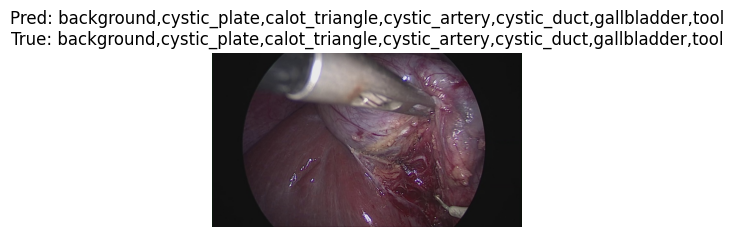

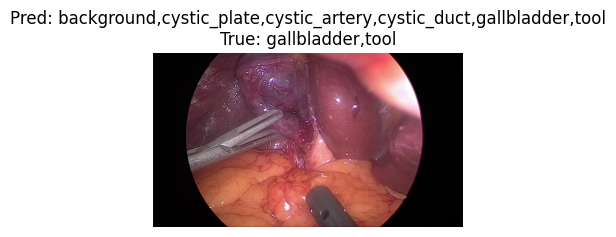

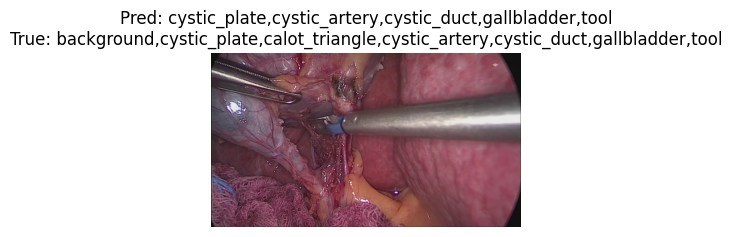

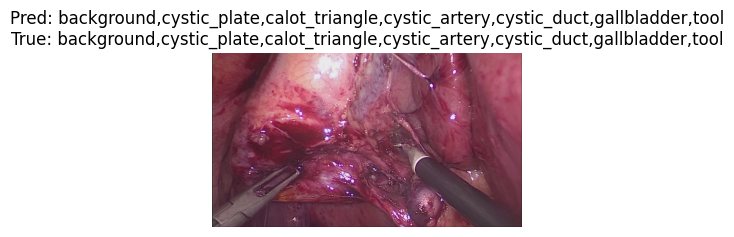

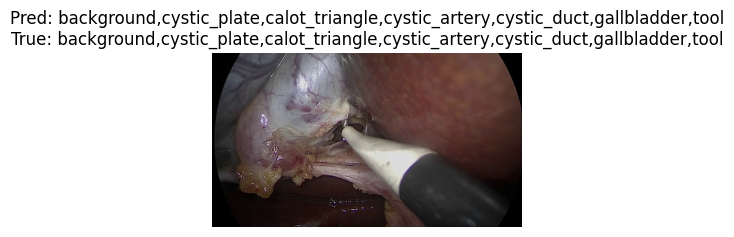

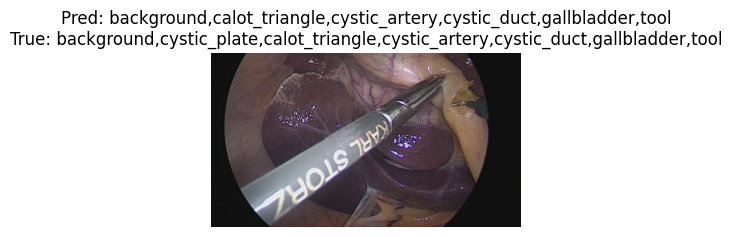

In [24]:
# Cell 4: visualize a few test samples with predicted labels
import matplotlib.pyplot as plt
import random
from PIL import Image

# pick random test items
n_show = 6
idxs = random.sample(range(len(X_test)), min(n_show, len(X_test)))
for i, idx in enumerate(idxs):
    emb = X_test[idx].reshape(1,-1)
    pred = clf.predict(scaler.transform(emb))[0]
    true = y_test[idx]
    # find filename by matching embedding stem in labels_df
    # naive: use X_test idx -> find in X_test rows (we lost filenames), so just show a random image from labels_df
    fname = labels_df.sample(1)['filename'].values[0]
    img = Image.open(IMAGE_ROOT / fname).convert('RGB')
    plt.figure(figsize=(4,4))
    plt.imshow(img); plt.axis('off')
    pred_tools = [label_cols[j] for j,v in enumerate(pred) if v==1]
    true_tools = [label_cols[j] for j,v in enumerate(true) if v==1]
    plt.title(f"Pred: {','.join(pred_tools)}\nTrue: {','.join(true_tools)}")
    plt.show()


In [27]:
# per-class threshold tuning (maximize F1 on validation)
from sklearn.metrics import f1_score, precision_recall_curve
import numpy as np

# assume we have X_train/X_val split earlier; but we can split X_train into train/val here:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

X_val_s = scaler.transform(X_val)
y_val_prob = clf.predict_proba(X_val_s)  # (n_val, C)

best_thresholds = []
for c in range(y.shape[1]):
    probs = y_val_prob[:, c]
    truth = y_val[:, c]
    if truth.sum() == 0:
        best_thresholds.append(0.5)
        continue
    precisions, recalls, thresh = precision_recall_curve(truth, probs)
    f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    # keep shape: precision, recall arrays length = len(thresh)+1, drop last element alignment
    best_idx = np.nanargmax(f1_scores[:-1]) if len(f1_scores)>1 else 0
    best_t = thresh[best_idx] if len(thresh)>0 else 0.5
    best_thresholds.append(float(best_t))

print("Per-class thresholds:", dict(zip(label_cols, np.round(best_thresholds,3))))

# Apply on test
X_test_s = scaler.transform(X_test)
y_test_prob = clf.predict_proba(X_test_s)
y_test_pred_tuned = (y_test_prob >= np.array(best_thresholds).reshape(1,-1)).astype(int)

# metrics after tuning
from sklearn.metrics import f1_score, average_precision_score
print("F1 micro (tuned):", f1_score(y_test, y_test_pred_tuned, average='micro'))
print("F1 macro (tuned):", f1_score(y_test, y_test_pred_tuned, average='macro'))
print("mAP (test):", np.mean([average_precision_score(y_test[:,i], y_test_prob[:,i]) for i in range(y.shape[1])]))


Per-class thresholds: {'background': 0.955, 'cystic_plate': 0.94, 'calot_triangle': 0.965, 'cystic_artery': 0.973, 'cystic_duct': 0.997, 'gallbladder': 0.996, 'tool': 1.0}
F1 micro (tuned): 0.9174917491749174
F1 macro (tuned): 0.9069068676823119
mAP (test): 0.9621977609194171


Loaded X,y,filenames: (1000, 2048) (1000, 7) (1000,)


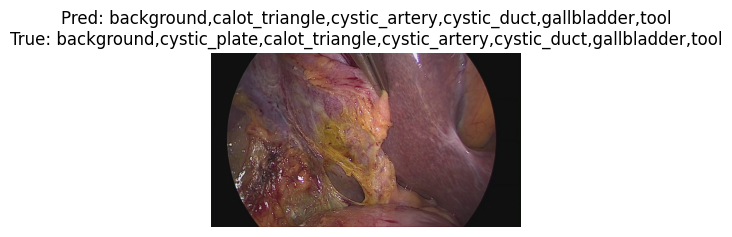

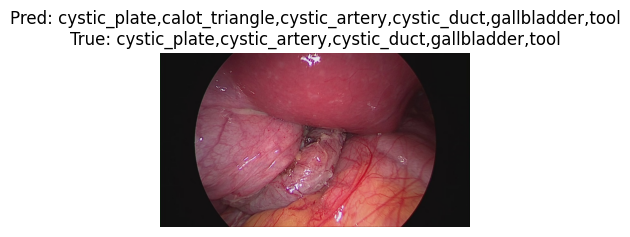

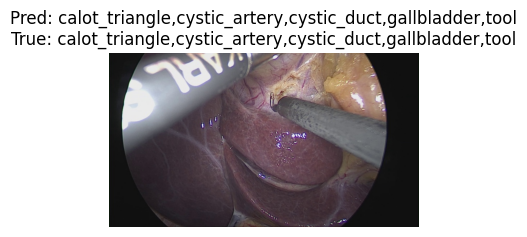

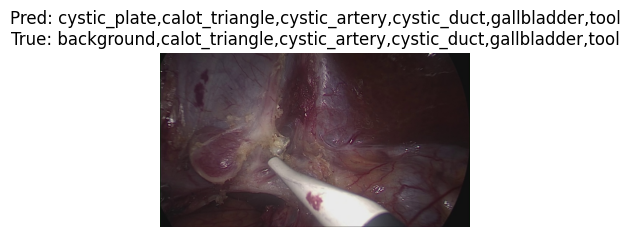

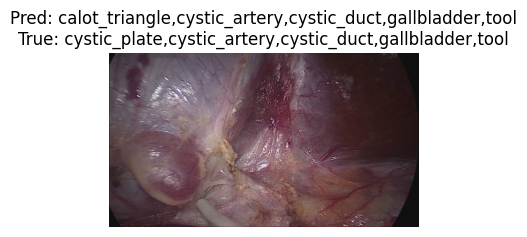

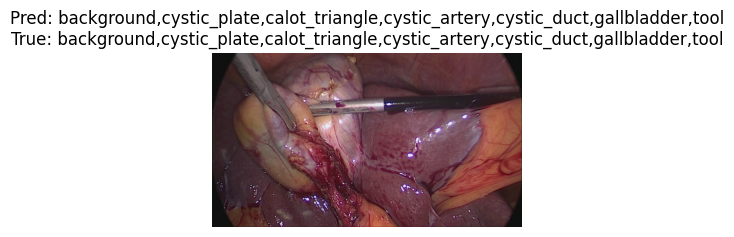

In [28]:
# FIXED visualization: preserves filenames so predictions match images
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

# Paths (adjust if needed)
EMBED_DIR = Path('/kaggle/working/endoscapes_small/embeddings')   # where .npy embeddings are
CSV_PATH  = Path('/kaggle/working/endoscapes_small/labels_train_subset_1000.csv')  # your subset CSV
IMAGE_ROOT = Path('/kaggle/working/endoscapes/endoscapes/train')  # images root

# Load labels df
labels_df = pd.read_csv(CSV_PATH)
label_cols = [c for c in labels_df.columns if c != 'filename']

# Build X, y and filename list (use embeddings you computed earlier)
X_list, y_list, fn_list = [], [], []
for _, row in labels_df.iterrows():
    stem = Path(row['filename']).stem
    emb_path = EMBED_DIR / (stem + '.npy')
    if not emb_path.exists():
        continue
    X_list.append(np.load(emb_path))
    y_list.append(row[label_cols].values.astype(int))
    fn_list.append(row['filename'])

X = np.stack(X_list)
y = np.stack(y_list)
filenames = np.array(fn_list)
print("Loaded X,y,filenames:", X.shape, y.shape, filenames.shape)

# Split while preserving filenames
X_train, X_test, y_train, y_test, fn_train, fn_test = train_test_split(
    X, y, filenames, test_size=0.20, random_state=42
)

# Load scaler & classifier you saved earlier (if applicable)
scaler = joblib.load('/kaggle/working/endoscapes_small/scaler_joblib.pkl')  # adjust path
clf = joblib.load('/kaggle/working/endoscapes_small/clf_joblib.pkl')

# Predict probs and apply threshold (default 0.5 for now)
X_test_s = scaler.transform(X_test)
y_prob = clf.predict_proba(X_test_s)    # shape (N, C)
y_pred = (y_prob >= 0.5).astype(int)

# Visualize first N test examples correctly
N = 6
for i in range(min(N, len(X_test))):
    fname = fn_test[i]
    img = Image.open(IMAGE_ROOT / fname).convert('RGB')
    pred_tools = [label_cols[j] for j,val in enumerate(y_pred[i]) if val==1]
    true_tools = [label_cols[j] for j,val in enumerate(y_test[i]) if val==1]
    plt.figure(figsize=(4,4))
    plt.imshow(img); plt.axis('off')
    plt.title(f"Pred: {','.join(pred_tools) or 'none'}\nTrue: {','.join(true_tools) or 'none'}")
    plt.show()


Using CSV: /kaggle/working/endoscapes_small/labels_train_subset_1000.csv
Loaded: (1000, 2048) (1000, 7) (1000,)
Train/Val/Test sizes: (640, 2048) (160, 2048) (200, 2048)

Per-class tuned thresholds:
background: 0.955
cystic_plate: 0.940
calot_triangle: 0.965
cystic_artery: 0.973
cystic_duct: 0.997
gallbladder: 0.996
tool: 1.000

Test metrics (tuned thresholds):
F1 micro: 0.9174917491749174
F1 macro: 0.9069068676823119
mAP: 0.9621977609194171

Classification report:
                precision    recall  f1-score   support

    background       0.86      0.74      0.79       146
  cystic_plate       0.85      0.76      0.80       151
calot_triangle       0.95      0.82      0.88       178
 cystic_artery       0.95      0.89      0.92       187
   cystic_duct       0.98      0.94      0.96       195
   gallbladder       1.00      0.98      0.99       198
          tool       1.00      0.99      0.99       199

     micro avg       0.95      0.89      0.92      1254
     macro avg       0.9

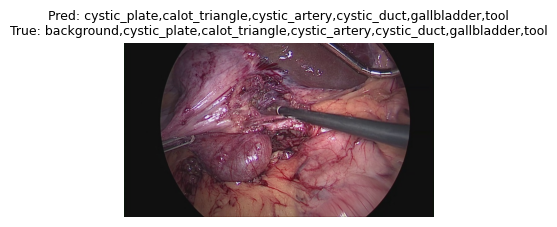

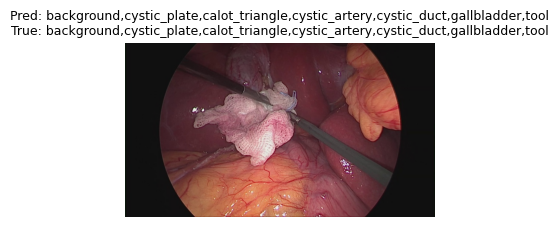

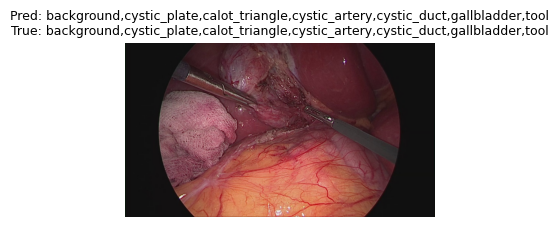

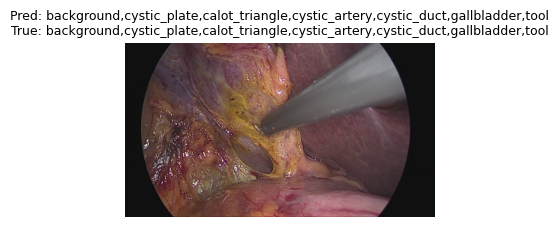

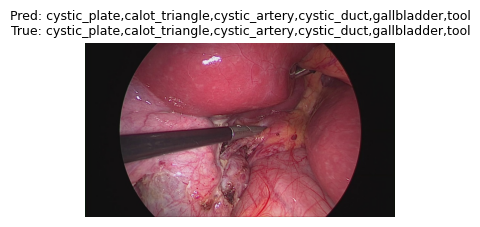

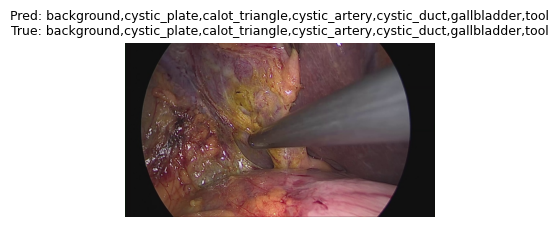

In [29]:
# === Combined tuned evaluation + correct visualization ===
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_recall_curve, average_precision_score, classification_report
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

# --- Paths (update if your filenames differ) ---
BASE = Path('/kaggle/working/endoscapes_small')
EMBED_DIR = BASE / 'embeddings'
CSV_PATH  = list(BASE.glob('labels_train_subset_*.csv'))[0]  # auto-find subset CSV
IMAGE_ROOT = Path('/kaggle/working/endoscapes/endoscapes/train')

print("Using CSV:", CSV_PATH)

# --- Load CSV ---
df = pd.read_csv(CSV_PATH)
label_cols = [c for c in df.columns if c != 'filename']

# --- Load embeddings & pair with filenames ---
X_list, y_list, fn_list = [], [], []
for _, row in df.iterrows():
    fname = row['filename']
    stem = Path(fname).stem
    emb_path = EMBED_DIR / f"{stem}.npy"
    if emb_path.exists():
        X_list.append(np.load(emb_path))
        y_list.append(row[label_cols].values.astype(int))
        fn_list.append(fname)

X = np.stack(X_list)
y = np.stack(y_list)
filenames = np.array(fn_list)

print("Loaded:", X.shape, y.shape, filenames.shape)

# --- Split into train/val/test with filenames preserved ---
X_temp, X_test, y_temp, y_test, fn_temp, fn_test = train_test_split(
    X, y, filenames, test_size=0.20, random_state=42
)

X_train, X_val, y_train, y_val, fn_train, fn_val = train_test_split(
    X_temp, y_temp, fn_temp, test_size=0.20, random_state=42
)

print("Train/Val/Test sizes:", X_train.shape, X_val.shape, X_test.shape)

# --- Load classifier + scaler you trained earlier ---
clf = joblib.load(BASE / 'clf_joblib.pkl')
scaler = joblib.load(BASE / 'scaler_joblib.pkl')

# --- Validation predictions ---
X_val_s = scaler.transform(X_val)
y_val_prob = clf.predict_proba(X_val_s)

# --- Per-class threshold tuning on validation ---
best_thresholds = []
for i in range(y.shape[1]):
    truth = y_val[:, i]
    probs = y_val_prob[:, i]
    
    # If class is empty in val set → default threshold
    if truth.sum() == 0:
        best_thresholds.append(0.5)
        continue
    
    precisions, recalls, thresholds = precision_recall_curve(truth, probs)
    f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    
    # Align lengths (PR curve quirk)
    f1s = f1s[:-1]  
    if len(thresholds) > 0:
        best_idx = np.argmax(f1s)
        best_thresholds.append(thresholds[best_idx])
    else:
        best_thresholds.append(0.5)

best_thresholds = np.array(best_thresholds)
print("\nPer-class tuned thresholds:")
for c, t in zip(label_cols, best_thresholds):
    print(f"{c}: {t:.3f}")

# --- Evaluate on test split ---
X_test_s = scaler.transform(X_test)
y_test_prob = clf.predict_proba(X_test_s)
y_pred_tuned = (y_test_prob >= best_thresholds.reshape(1, -1)).astype(int)

print("\nTest metrics (tuned thresholds):")
print("F1 micro:", f1_score(y_test, y_pred_tuned, average='micro'))
print("F1 macro:", f1_score(y_test, y_pred_tuned, average='macro'))
print("mAP:", np.mean([
    average_precision_score(y_test[:, i], y_test_prob[:, i]) 
    for i in range(y_test.shape[1])
]))

print("\nClassification report:")
print(classification_report(y_test, y_pred_tuned, target_names=label_cols, zero_division=0))

# --- Correct visualization: show prediction + truth for matching filenames ---
N = 6  # number of samples to show
idxs = np.random.choice(len(X_test), size=min(N, len(X_test)), replace=False)

for i in idxs:
    fname = fn_test[i]
    img = Image.open(IMAGE_ROOT / fname).convert('RGB')
    pred = y_pred_tuned[i]
    true = y_test[i]
    pred_labels = [label_cols[j] for j,v in enumerate(pred) if v==1]
    true_labels = [label_cols[j] for j,v in enumerate(true) if v==1]
    
    plt.figure(figsize=(4,4))
    plt.imshow(img); plt.axis('off')
    plt.title(
        "Pred: " + (",".join(pred_labels) or "none") +
        "\nTrue: " + (",".join(true_labels) or "none"),
        fontsize=9
    )
    plt.show()


device: cuda | checkpoint exists: False
SAM checkpoint not found at /kaggle/working/sam_vit_b_01ec64.pth


/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Subset rows to embed: 1000


SAM embed:   0%|          | 0/1000 [00:00<?, ?it/s]

Loaded embeddings matrix: (1000, 2048) labels: (1000, 7)
Train/Val/Test sizes: 640 160 200
Per-class thresholds: [0.041 0.002 0.141 0.094 0.989 0.91  1.   ]
F1 micro: 0.9431643625192013
F1 macro: 0.9390250268007243
mAP: 0.9632087409327019

Per-class support / positives:
background: support=756
cystic_plate: support=790
calot_triangle: support=882
cystic_artery: support=927
cystic_duct: support=972
gallbladder: support=981
tool: support=985

Classification report (test):
                precision    recall  f1-score   support

    background       0.76      0.95      0.84       146
  cystic_plate       0.77      0.97      0.86       151
calot_triangle       0.90      0.97      0.93       178
 cystic_artery       0.94      0.99      0.97       187
   cystic_duct       0.98      0.98      0.98       195
   gallbladder       0.99      1.00      1.00       198
          tool       1.00      0.99      0.99       199

     micro avg       0.91      0.98      0.94      1254
     macro avg     

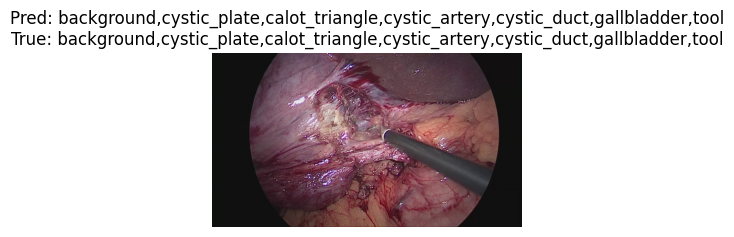

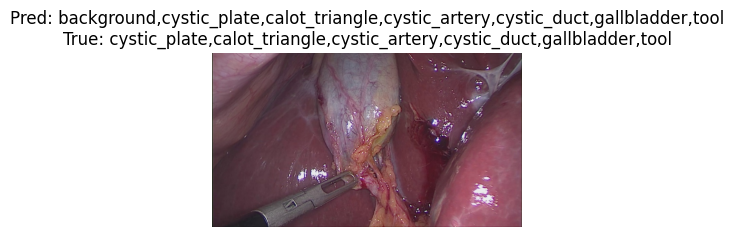

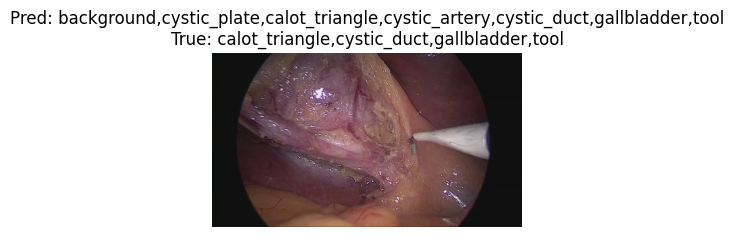

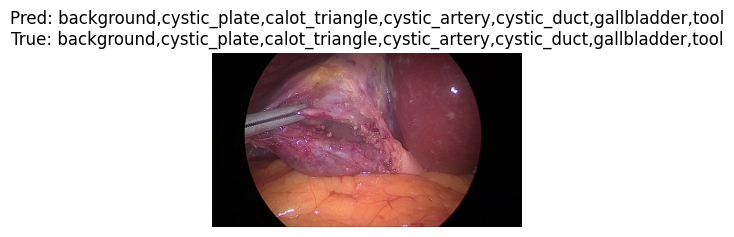

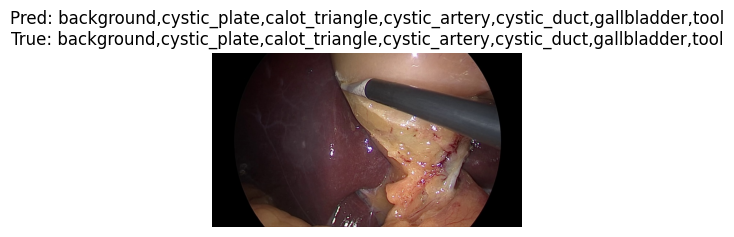

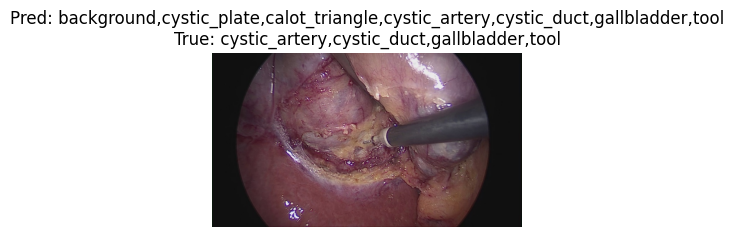

In [30]:
# === SAM-B (sam_vit_b_01ec64.pth) embeddings -> PCA(2048) -> OVR classifier ===
# Single cell: compute SAM embeddings for your subset, compress, train, tune, eval, visualize.
import os
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
import torch
import joblib
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, average_precision_score, precision_recall_curve, classification_report
import matplotlib.pyplot as plt

# ---------- paths / config ----------
CKPT = Path('/kaggle/working/sam_vit_b_01ec64.pth')   # your downloaded checkpoint
SUBSET_BASE = Path('/kaggle/working/endoscapes_small')  # where subset CSV lives
SUBSET_CSV = list(SUBSET_BASE.glob('labels_train_subset_*.csv'))[0]  # auto-find
IMAGE_ROOT = Path('/kaggle/working/endoscapes/endoscapes/train')
EMBED_DIR = SUBSET_BASE / 'sam_embeddings'   # new folder for SAM vectors
EMBED_DIR.mkdir(parents=True, exist_ok=True)

PCA_DIM = 2048   # compress SAM vectors to this dim so downstream stays same shape
SAMPLE_LIMIT = None  # None -> use all rows in subset CSV. You can set small integer for quick test.

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("device:", DEVICE, "| checkpoint exists:", CKPT.exists())

# ---------- try to load SAM model (fallback to ResNet if anything goes wrong) ----------
use_sam = False
sam_model = None
try:
    from segment_anything import sam_model_registry
    if CKPT.exists():
        sam_model = sam_model_registry["vit_b"](checkpoint=str(CKPT))
        sam_model.to(DEVICE)
        sam_model.eval()
        print("Loaded SAM-B checkpoint")
        use_sam = True
    else:
        print("SAM checkpoint not found at", CKPT)
except Exception as e:
    print("Could not import/load SAM; will fallback to ResNet. Error:", e)

# ---------- define SAM embedding function (robust) ----------
if use_sam:
    import torch.nn.functional as F
    def compute_sam_vec(img_pil):
        # produce a single vector per image by calling common SAM encoder hooks and pooling
        img = img_pil.convert('RGB')
        tensor = torch.from_numpy(np.array(img).astype(np.float32) / 255.0).permute(2,0,1).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            emb = None
            # try common methods
            if hasattr(sam_model, "get_image_embedding"):
                try:
                    emb = sam_model.get_image_embedding(tensor)  # often returns [1, C, H, W] or [1, C]
                except Exception:
                    emb = None
            if emb is None and hasattr(sam_model, "encoder"):
                try:
                    emb = sam_model.encoder(tensor)
                except Exception:
                    emb = None
            if emb is None and hasattr(sam_model, "image_encoder"):
                try:
                    emb = sam_model.image_encoder(tensor)
                except Exception:
                    emb = None
            if emb is None and hasattr(sam_model, "img_encoder"):
                try:
                    emb = sam_model.img_encoder(tensor)
                except Exception:
                    emb = None
            if emb is None:
                raise RuntimeError("SAM encoder API not found on model object.")
            # normalize to 1D vector
            if emb.dim() == 2:
                vec = emb.squeeze(0).cpu().numpy()
            elif emb.dim() == 4:
                pooled = F.adaptive_avg_pool2d(emb, (1,1))
                vec = pooled.view(pooled.size(0), -1).squeeze(0).cpu().numpy()
            else:
                vec = emb.view(emb.size(0), -1).squeeze(0).cpu().numpy()
        return vec
else:
    # ResNet fallback embedding (guaranteed)
    from torchvision import models, transforms
    import torch.nn as nn
    resnet = models.resnet50(pretrained=True)
    resnet_fc = nn.Sequential(*list(resnet.children())[:-1])
    if DEVICE == 'cuda' and torch.cuda.device_count() > 1:
        resnet_fc = torch.nn.DataParallel(resnet_fc)
    resnet_fc.to(DEVICE)
    resnet_fc.eval()
    preprocess = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])
    ])
    def compute_sam_vec(img_pil):
        t = preprocess(img_pil).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            out = resnet_fc(t)
            out = out.view(out.size(0), -1).cpu().numpy().squeeze()
        return out

# ---------- load subset CSV (possibly limited) ----------
df = pd.read_csv(SUBSET_CSV)
if SAMPLE_LIMIT:
    df = df.sample(SAMPLE_LIMIT, random_state=42).reset_index(drop=True)
print("Subset rows to embed:", len(df))

# ---------- compute embeddings (skip existing .npy) ----------
filenames = df['filename'].tolist()
for fname in tqdm(filenames, desc="SAM embed"):
    emb_path = EMBED_DIR / (Path(fname).stem + '.npy')
    if emb_path.exists():
        continue
    img_path = IMAGE_ROOT / fname
    if not img_path.exists():
        # try alternate potential locations
        # (if your images are in nested folders, you can add recursive lookup here)
        print("Missing image file:", img_path)
        continue
    try:
        img = Image.open(img_path).convert('RGB')
        vec = compute_sam_vec(img)
        np.save(emb_path, vec)
    except Exception as e:
        print("Failed:", fname, "error:", e)

# ---------- collect embeddings into matrix ----------
emb_files = sorted(list(EMBED_DIR.glob('*.npy')))
emb_map = {p.stem: str(p) for p in emb_files}
Xlist, ylist, fnlist = [], [], []
label_cols = [c for c in df.columns if c != 'filename']
for _, r in df.iterrows():
    stem = Path(r['filename']).stem
    if stem in emb_map:
        Xlist.append(np.load(emb_map[stem]))
        ylist.append(r[label_cols].values.astype(int))
        fnlist.append(r['filename'])
X = np.stack(Xlist)
y = np.stack(ylist)
filenames = np.array(fnlist)
print("Loaded embeddings matrix:", X.shape, "labels:", y.shape)

# ---------- PCA reduction to PCA_DIM (only if vector dim != PCA_DIM) ----------
orig_dim = X.shape[1]
if orig_dim != PCA_DIM:
    print(f"Running PCA to reduce {orig_dim} -> {PCA_DIM} (fit on subset embeddings).")
    pca = PCA(n_components=PCA_DIM, whiten=False, random_state=42)
    X_pca = pca.fit_transform(X)
    joblib.dump(pca, SUBSET_BASE / 'sam_pca_{}.joblib'.format(PCA_DIM))
    X_use = X_pca
else:
    X_use = X

# ---------- train / val / test split (preserve filenames) ----------
X_temp, X_test, y_temp, y_test, fn_temp, fn_test = train_test_split(X_use, y, filenames, test_size=0.20, random_state=42)
X_train, X_val, y_train, y_val, fn_train, fn_val = train_test_split(X_temp, y_temp, fn_temp, test_size=0.20, random_state=42)
print("Train/Val/Test sizes:", X_train.shape[0], X_val.shape[0], X_test.shape[0])

# ---------- standardize, train classifier ----------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

clf = OneVsRestClassifier(LogisticRegression(max_iter=1000))
clf.fit(X_train_s, y_train)

# ---------- tune per-class thresholds on validation ----------
y_val_prob = clf.predict_proba(X_val_s)
best_thresholds = []
for c in range(y.shape[1]):
    truth = y_val[:, c]
    probs = y_val_prob[:, c]
    if truth.sum() == 0:
        best_thresholds.append(0.5)
        continue
    precision, recall, thr = precision_recall_curve(truth, probs)
    f1s = 2 * precision * recall / (precision + recall + 1e-12)
    f1s = f1s[:-1]  # align
    if len(thr) > 0:
        best_thresholds.append(float(thr[np.argmax(f1s)]))
    else:
        best_thresholds.append(0.5)
best_thresholds = np.array(best_thresholds)
print("Per-class thresholds:", np.round(best_thresholds,3))

# ---------- evaluate on test ----------
y_test_prob = clf.predict_proba(X_test_s)
y_test_pred = (y_test_prob >= best_thresholds.reshape(1,-1)).astype(int)

print("F1 micro:", f1_score(y_test, y_test_pred, average='micro'))
print("F1 macro:", f1_score(y_test, y_test_pred, average='macro'))
print("mAP:", np.mean([average_precision_score(y_test[:,i], y_test_prob[:,i]) for i in range(y.shape[1])]))

print("\nPer-class support / positives:")
for i,col in enumerate(label_cols):
    print(f"{col}: support={y[:,i].sum()}")

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, target_names=label_cols, zero_division=0))

# ---------- save artifacts ----------
joblib.dump(clf, SUBSET_BASE / 'sam_clf.joblib')
joblib.dump(scaler, SUBSET_BASE / 'sam_scaler.joblib')
if 'pca' in locals():
    joblib.dump(pca, SUBSET_BASE / 'sam_pca.joblib')
print("Saved classifier/scaler (and pca if used) to", SUBSET_BASE)

# ---------- visualize a few matched test images with predictions ----------
N = 6
idxs = np.random.choice(len(X_test), size=min(N,len(X_test)), replace=False)
for i in idxs:
    fname = fn_test[i]
    img = Image.open(IMAGE_ROOT / fname).convert('RGB')
    pred = y_test_pred[i]
    true = y_test[i]
    pred_labels = [label_cols[j] for j,v in enumerate(pred) if v==1]
    true_labels = [label_cols[j] for j,v in enumerate(true) if v==1]
    plt.figure(figsize=(4,4))
    plt.imshow(img); plt.axis('off')
    plt.title("Pred: " + (",".join(pred_labels) or "none") + "\nTrue: " + (",".join(true_labels) or "none"))
    plt.show()


In [3]:
!ls -R /kaggle/working


/kaggle/working:
endoscapes_small

/kaggle/working/endoscapes_small:
